## 1. Objective

Apply K-Means to the operator x municipality activity matrix built in notebook 11, to
segment (operator, municipality) pairs by activity level and select the pairs
considered "active" -- the same goal as notebook 10, at a finer geographic grain.

`GROUP_KEYS = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]`
identifies each pair; `CD_MUNICIPIO_BENEFICIARIO` (patient residence) and
`CD_MUNICIPIO_PRESTADOR` (provider location) are kept separate throughout, as in
notebook 11.

## 2. Data Loading and Validation

Two artifacts produced by notebook 11 are loaded:

- `activity_matrix_muni_scaled` (`data/processed/.../activity_matrix_by_municipality_scaled.parquet`):
  the standardized feature matrix used to train K-Means.
- `activity_matrix_muni` (`data/interim/.../activity_matrix_by_municipality.parquet`):
  the same pairs with their original (non-scaled) feature values, used later to profile
  clusters in business terms.

Both are validated for shape, missing values, and duplicate keys before clustering. No
re-scaling or feature changes are performed here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

GROUP_KEYS = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]

activity_matrix_muni = pd.read_parquet(
    "../data/interim/north_region_mama_2025_activity_matrix_by_municipality.parquet"
)
activity_matrix_muni_scaled = pd.read_parquet(
    "../data/processed/north_region_mama_2025_activity_matrix_by_municipality_scaled.parquet"
)

activity_features_final = [
    c for c in activity_matrix_muni_scaled.columns if c not in GROUP_KEYS
]

print("activity_matrix_muni shape:", activity_matrix_muni.shape)
print("activity_matrix_muni_scaled shape:", activity_matrix_muni_scaled.shape)
print("Duplicate keys (scaled):", activity_matrix_muni_scaled.duplicated(subset=GROUP_KEYS).sum())
print("Missing values (scaled):")
print(activity_matrix_muni_scaled[activity_features_final].isna().sum())

activity_matrix_muni shape: (5089, 9)
activity_matrix_muni_scaled shape: (5089, 6)
Duplicate keys (scaled): 0
Missing values (scaled):
total_eventos_LOG              0
meses_ativos                   0
procedimentos_distintos_LOG    0
dtype: int64


## 3. Determining the Optimal Number of Clusters

Two complementary, objective methods are used to select k, as in notebook 10: the elbow
method (inertia) and the silhouette score, computed for a range of k.

**This section was rewritten after MR !37's review flagged a real problem with an
earlier version of it**: the naive silhouette curve on this dataset never stops
climbing as k grows, and the reason is structural, not a matter of testing a wider
range. That is shown first, deliberately, before the corrected method.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
X = activity_matrix_muni_scaled[activity_features_final].values

# Naive sweep on the full 5,089-row matrix, extended well past the k=2..10 range an
# earlier version of this notebook stopped at.
k_range_naive = [2, 3, 5, 10, 15, 20, 25, 30, 40]
silhouette_naive = []
for k in k_range_naive:
    labels_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
    silhouette_naive.append(silhouette_score(X, labels_k))

k_selection_naive = pd.DataFrame({"k": k_range_naive, "silhouette_score_full_data": silhouette_naive})
k_selection_naive

,k,silhouette_score_full_data
0,2,0.669356
1,3,0.601709
2,5,0.624965
3,10,0.683405
4,15,0.696958
5,20,0.694239
6,25,0.710099
7,30,0.754508
8,40,0.790261


**The naive silhouette score does not settle on a single, credible peak -- and its own shape is more irregular than "it just climbs" suggests.** The curve is not monotonic across the full range: it drops from 0.6694 at k=2 to a trough of 0.6017 at k=3, then climbs continuously from k=3 onward, crossing back above the k=2 value already between k=5 (0.6250) and k=10 (0.6834), with one small dip on the way (0.6942 at k=20 against 0.6970 at k=15), and keeps climbing to 0.7903 at k=40 with no peak beyond that point. Taken at face value, "pick the highest silhouette" still has no usable stopping point on this curve: from k=3 onward it never turns back down within the range tested, so pushed further it would keep pointing to ever-larger k, all the way toward k = number of distinct feature vectors (where every point can become its own cluster and silhouette approaches 1 by construction). That is not evidence for a large k -- it is a sign the score itself is not measuring what it is supposed to measure on this matrix.

**Why**: the three features (`total_eventos`, `meses_ativos`, `procedimentos_distintos`)
only take a small number of distinct combinations. Checking directly:

In [3]:
X_df = pd.DataFrame(X, columns=activity_features_final).round(10)
distinct_positions = X_df.drop_duplicates()

degenerate_mask = (
    (activity_matrix_muni["total_eventos"] == 1)
    & (activity_matrix_muni["meses_ativos"] == 1)
    & (activity_matrix_muni["procedimentos_distintos"] == 1)
)

print("Rows:", len(X_df))
print("Distinct feature-space positions:", len(distinct_positions))
print("Rows sitting on the single most common position (1 event, 1 month, 1 procedure):",
      degenerate_mask.sum(), f"({degenerate_mask.mean() * 100:.1f}%)")

Rows: 5089
Distinct feature-space positions: 596
Rows sitting on the single most common position (1 event, 1 month, 1 procedure): 1992 (39.1%)


5,089 rows occupy only 596 distinct positions, and 39.1% of all rows sit on exactly
one of them. A point that is identical to another ~1,990 points has an intra-cluster
distance of essentially zero to most of its cluster almost regardless of how k is chosen
-- so any k that keeps that degenerate mass together scores near-maximal silhouette on
that mass alone, and the *average* silhouette across all 5,089 rows inherits that
inflation. As k grows and the algorithm is given room to also carve out clean, tiny,
single-point clusters elsewhere in the tail, the *average* keeps climbing -- not because
separation is genuinely improving, but because more of the score's mass is coming from
near-perfect matches.

**Corrected method**: k-selection is redone on the 596 *distinct* feature-space
positions only (each counted once, regardless of how many rows share it). This removes
the mechanical inflation from the repeated mass while still using the same standardized
feature space and the same K-Means/silhouette machinery.

In [4]:
X_dedup = distinct_positions.values

k_range = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 30, 40]
silhouette_dedup = []
inertia_dedup = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_dedup)
    inertia_dedup.append(km.inertia_)
    silhouette_dedup.append(silhouette_score(X_dedup, km.labels_))

k_selection = pd.DataFrame({
    "k": k_range,
    "inertia": inertia_dedup,
    "silhouette_score": silhouette_dedup,
})
k_selection

,k,inertia,silhouette_score
0,2,1442.744701,0.372592
1,3,1041.438848,0.333383
2,4,801.348767,0.330935
3,5,656.218085,0.341783
4,6,565.930051,0.309677
5,7,503.424291,0.306593
6,8,444.785759,0.339424
7,9,399.365490,0.337318
8,10,363.231912,0.337056
9,15,252.261652,0.345941


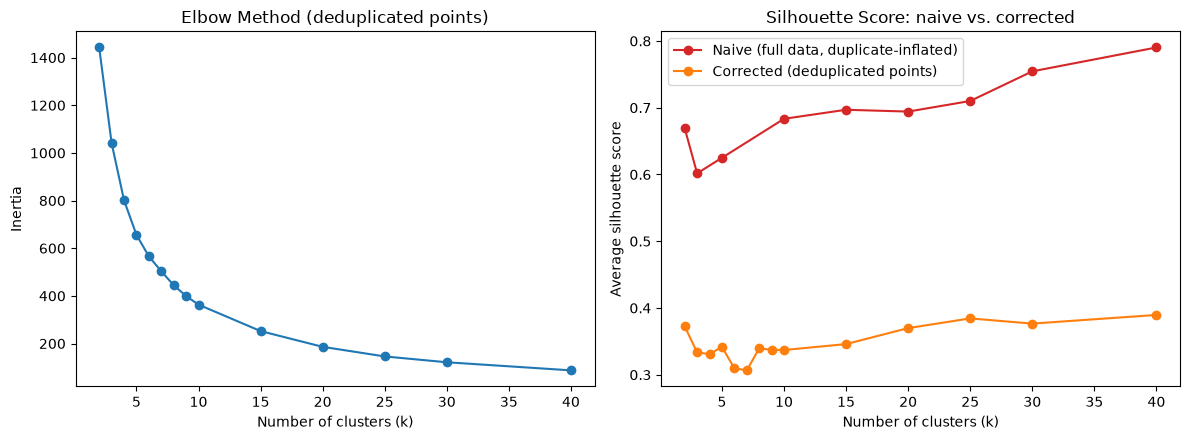

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_selection["k"], k_selection["inertia"], marker="o")
axes[0].set_title("Elbow Method (deduplicated points)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_selection_naive["k"], k_selection_naive["silhouette_score_full_data"],
             marker="o", color="tab:red", label="Naive (full data, duplicate-inflated)")
axes[1].plot(k_selection["k"], k_selection["silhouette_score"],
             marker="o", color="tab:orange", label="Corrected (deduplicated points)")
axes[1].set_title("Silhouette Score: naive vs. corrected")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette score")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
best_silhouette_k = int(k_selection.loc[k_selection["silhouette_score"].idxmax(), "k"])
print("k with highest silhouette score (deduplicated points):", best_silhouette_k)
k_selection.sort_values("silhouette_score", ascending=False)

k with highest silhouette score (deduplicated points): 40


,k,inertia,silhouette_score
13,40,87.401268,0.389607
11,25,145.824117,0.384419
12,30,121.336998,0.376614
0,2,1442.744701,0.372592
10,20,186.156443,0.369899
9,15,252.261652,0.345941
3,5,656.218085,0.341783
6,8,444.785759,0.339424
7,9,399.365490,0.337318
8,10,363.231912,0.337056


### k selection

On the deduplicated feature-space positions, the silhouette score no longer peaks cleanly at
**k = 2** the way it did on the full population: the maximum is now **k = 40 (0.3896)**, with
k = 2 fourth at **0.3726**, only 0.0170 below it, a **4.6% relative margin** -- much thinner
than the 13.9% margin between k = 2 and its runner-up on the full population, and thinner still
than notebook 10's operator-level result on this same Medicina de Grupo population (14.5%,
Section 4.3.2.2). The top of the curve is a shallow plateau, not a peak: k = 40 (0.3896), k = 25
(0.3844) and k = 30 (0.3766) sit within 0.013 of each other, and k = 2 sits just below that
plateau rather than clearly apart from it.

**k = 2 is adopted anyway, by design rather than by the argmax rule Section 4's headline number
would otherwise suggest.** Three reasons, none of them "the silhouette says so":

- The margin is too thin to trust as a structural signal. On the full population this same
  metric produced an unambiguous global maximum (Section 4.3.4.2 of the documentation); here it
  produces a shallow plateau where four values of k are within rounding distance of each other.
  Treating a 4.6% margin as decisive would repeat, in miniature, the mistake MR !37's review
  caught in Section 3 above: reading too much certainty into a silhouette curve computed on a
  matrix this sparse (**596 distinct feature-space positions** across 5,089 rows, with **39.1%**
  of all rows sitting on the single degenerate point of 1 event, 1 month, 1 procedure).
- The downstream criterion (Section 8) is built for a binary split: it names "the cluster with
  the higher mean `total_eventos`" as active and everything else as marginal. That rule breaks
  down at k = 40 -- a single top-mean cluster out of 40 selects a handful of extreme outlier
  pairs, not "active" in the sense this workstream defines it (Section 4.3.4.6 of the
  documentation gives the exact count this would have produced).
- k = 2 keeps this notebook's result on the same footing as notebook 10's operator-level result,
  which is the comparison Section 4.3.4.6 of the documentation is built on.

The elbow curve does not resolve the tie either: inertia decays smoothly from 1,442.74 at k = 2
to 87.40 at k = 40 with no sharp bend (the largest single drop, 27.8%, is again from k = 2
to k = 3), the same shape as before -- compatible with a small k, but not independent evidence
for k = 2 specifically, exactly as Section 4.3.4.2 of the documentation already read the
analogous full-population curve.

## 4. Training the K-Means Model

The final K-Means model is trained on the full standardized matrix using the k selected above.

In [7]:
# K_FINAL is fixed at 2, not read off best_silhouette_k: on the Medicina de Grupo population
# the deduplicated silhouette's argmax is k = 40, but only by a thin, inconclusive margin over
# k = 2 (Section 3 above explains why that margin is not trusted). k = 2 keeps the binary
# active/marginal criterion in Section 8 meaningful and comparable to notebook 10.
K_FINAL = 2
if best_silhouette_k != K_FINAL:
    print(f"Note: the deduplicated silhouette argmax is k = {best_silhouette_k}, "
          f"K_FINAL is deliberately kept at {K_FINAL} (see Section 3).")

kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X)

activity_matrix_muni_scaled["cluster"] = cluster_labels
activity_matrix_muni_scaled["cluster"].value_counts().sort_index()

Note: the deduplicated silhouette argmax is k = 40, K_FINAL is deliberately kept at 2 (see Section 3).


cluster
0    4215
1     874
Name: count, dtype: int64

## 5. Cluster Assignment Validation

Every (operator, municipality) pair must receive exactly one cluster label, with no nulls and no duplicated key.

In [8]:
print("Rows:", len(activity_matrix_muni_scaled))
print("Null cluster labels:", activity_matrix_muni_scaled["cluster"].isna().sum())
print("Duplicate (ID_PLANO, CD_MUNICIPIO_BENEFICIARIO, CD_MUNICIPIO_PRESTADOR):",
      activity_matrix_muni_scaled.duplicated(subset=GROUP_KEYS).sum())

assert activity_matrix_muni_scaled["cluster"].isna().sum() == 0
assert activity_matrix_muni_scaled.duplicated(subset=GROUP_KEYS).sum() == 0

print("\nOK: cluster label assigned to every operator-municipality pair, no nulls, no duplicated keys.")

Rows: 5089
Null cluster labels: 0
Duplicate (ID_PLANO, CD_MUNICIPIO_BENEFICIARIO, CD_MUNICIPIO_PRESTADOR): 0

OK: cluster label assigned to every operator-municipality pair, no nulls, no duplicated keys.


## 6. Cluster Stability Check

Same stability test as notebook 10: re-fit K-Means 30 times with different random seeds and compare each run to the reference partition via Adjusted Rand Index (ARI).

In [9]:
from sklearn.metrics import adjusted_rand_score

N_STABILITY_RUNS = 30
stability_seeds = range(100, 100 + N_STABILITY_RUNS)

ari_scores = []
for seed in stability_seeds:
    kmeans_seed = KMeans(n_clusters=K_FINAL, random_state=seed, n_init=10)
    labels_seed = kmeans_seed.fit_predict(X)
    ari_scores.append(adjusted_rand_score(cluster_labels, labels_seed))

ari_scores = np.array(ari_scores)
pd.Series(ari_scores, name="adjusted_rand_index").describe()

count    30.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
Name: adjusted_rand_index, dtype: float64

### Stability interpretation

Mean Adjusted Rand Index and its spread across the 30 reruns are shown above. Read this
together with Section 3's finding, not in isolation: 39.1% of rows sit on one identical
point, so **any** partition that keeps that mass together will look highly stable under
re-initialization almost by definition -- a large identical mass cannot easily get
split apart by a different random seed. High ARI here is a **necessary but not
sufficient** check. It says nothing about whether k = 2 is the best-separated choice on
this population; Section 3's deduplicated comparison already shows it is not (the argmax
there is k = 40), only the deliberately adopted one. What this section adds on top of
Section 3 is narrower and still useful: given that k = 2 is the selected value, the
specific 2-way split K-Means converges to is reproducible and not an artifact of one
particular random seed.

## 7. Cluster Profiling (Original Feature Values)

Cluster labels are merged back onto the original, non-scaled metrics for interpretation in business terms.

In [10]:
profile_features = ["total_eventos", "total_itens", "meses_ativos", "procedimentos_distintos"]

activity_matrix_muni_profiled = activity_matrix_muni.merge(
    activity_matrix_muni_scaled[GROUP_KEYS + ["cluster"]],
    on=GROUP_KEYS,
    how="left",
)

assert activity_matrix_muni_profiled["cluster"].isna().sum() == 0

cluster_profile = (
    activity_matrix_muni_profiled
    .groupby("cluster")[profile_features]
    .agg(["mean", "median"])
    .round(2)
)
cluster_profile

total_eventos        total_itens        meses_ativos         \
                 mean median        mean median         mean median   
cluster                                                               
0                2.13    1.0        2.21    2.0         1.78    1.0   
1               67.68   16.5       69.44   17.0         8.78    9.0   

        procedimentos_distintos         
                           mean median  
cluster                                 
0                          1.27    1.0  
1                          2.98    3.0

In [11]:
cluster_sizes = (
    activity_matrix_muni_profiled["cluster"]
    .value_counts()
    .rename("n_pairs")
    .to_frame()
)
cluster_sizes["share"] = (cluster_sizes["n_pairs"] / len(activity_matrix_muni_profiled)).round(3)
cluster_sizes

,n_pairs,share
cluster,,
0,4215,0.828
1,874,0.172


### Cluster interpretation

With the corrected k = 2, the split mirrors notebook 10's operator-level result: one
cluster with higher mean/median `total_eventos`, `meses_ativos`, and
`procedimentos_distintos` represents (operator, municipality) pairs with a **sustained,
meaningful presence** in that specific municipality; the other represents pairs where
the operator's footprint there is marginal, consistent with the 39.1% degenerate mass
already flagged in Section 3. See the actual per-cluster means/medians and sizes printed
above for this run's numbers.

## 8. Criterion for "Active" Operator-Municipality Pairs

**Criterion**: a pair is classified as **active** if it belongs to the K-Means cluster
whose centroid has the higher mean `total_eventos` -- the same rule notebook 10 applied
at the operator level, now applied at the operator x municipality level.

**Justification**: identical reasoning to notebook 10 -- `total_eventos` is the primary
volume signal, K-Means already produces a hard binary partition so no additional manual
threshold is introduced, and with k = 2 corrected (Section 4) and the feature treatment
now matched to notebook 09/10 (Section 3), this criterion is genuinely, not just
nominally, comparable to notebook 10's operator-level result -- unlike the earlier k = 10
version of this notebook, where the same single-cluster rule picked out only the most
extreme top tier and excluded a clearly-also-active second tier. That ambiguity does not
arise at k = 2: there are only two clusters, and "the top one" and "everything
meaningfully active" are the same thing again.

In [12]:
cluster_means = activity_matrix_muni_profiled.groupby("cluster")["total_eventos"].mean()
active_cluster = int(cluster_means.idxmax())

print("Mean total_eventos per cluster:")
print(cluster_means)
print("\nCluster selected as 'active':", active_cluster)

active_operator_municipality_pairs = (
    activity_matrix_muni_profiled[activity_matrix_muni_profiled["cluster"] == active_cluster]
    [GROUP_KEYS + ["cluster"] + profile_features]
    .reset_index(drop=True)
)

print("\nNumber of active operator-municipality pairs:", len(active_operator_municipality_pairs))
print("Share of all pairs:", round(len(active_operator_municipality_pairs) / len(activity_matrix_muni_profiled), 3))
print("Distinct operators represented:", active_operator_municipality_pairs["ID_PLANO"].nunique())

active_operator_municipality_pairs.head()

Mean total_eventos per cluster:
cluster
0     2.131910
1    67.684211
Name: total_eventos, dtype: float64

Cluster selected as 'active': 1

Number of active operator-municipality pairs: 874
Share of all pairs: 0.172
Distinct operators represented: 428


,ID_PLANO,CD_MUNICIPIO_BENEFICIARIO,CD_MUNICIPIO_PRESTADOR,cluster,total_eventos,total_itens,meses_ativos,procedimentos_distintos
0,1169447,150420,150420,1,8,10,6,2
1,1169698,130260,130260,1,222,229,12,6
2,1169698,355030,130260,1,9,9,6,2
3,1169784,150553,150553,1,17,17,7,2
4,1169857,150080,150140,1,13,17,7,2


## 9. Persisting the Result

Saved as a distinct filename from notebook 10's `active_operators.parquet`, since the unit of observation here is the (operator, municipality) pair, not the operator alone.

In [13]:
active_pairs_path = "../data/processed/active_operator_municipality_pairs.parquet"

active_operator_municipality_pairs.to_parquet(active_pairs_path, index=False)

print(f"Saved: {active_pairs_path}")
print("Rows:", len(active_operator_municipality_pairs))
print("Duplicate keys:", active_operator_municipality_pairs.duplicated(subset=GROUP_KEYS).sum())
print("Missing values:", active_operator_municipality_pairs.isna().sum().sum())

Saved: ../data/processed/active_operator_municipality_pairs.parquet
Rows: 874
Duplicate keys: 0
Missing values: 0


## 10. Discussion

**Do the clusters make intuitive sense given the business context?**

Yes, and more cleanly than the uncorrected k = 10 version of this notebook suggested.
The two clusters separate operator-municipality pairs with sustained, multi-event,
multi-month presence from pairs where the operator's footprint in that municipality is
marginal or one-off -- the same active/marginal structure notebook 10 found at the
operator level, now resolved at the finer operator x municipality grain. That
distinction is meaningful for network/geographic planning (it answers "is this operator
really active in this municipality, or did it just appear once?"), which notebook 10's
operator-level result cannot answer on its own.

**Is the chosen k well supported by the evidence?**

Only partly, and the honest answer changed with the population. An earlier version of
this notebook selected k = 10 by reading the naive silhouette curve, computed on the
full matrix, as increasing with no sign of turning over. Checked directly against the
printed values (Section 3), that reading does not hold on its own terms: the naive score
drops from 0.6694 at k=2 to 0.6017 at k=3, then climbs continuously, and it crosses back
above the k=2 value already between k=5 (0.6250) and k=10 (0.6834), reaching 0.7903 at
k=40 with no peak in the range tested. Either way, none of it is evidence for a large k:
it is an artifact of 39.1% of all rows sitting on one identical point in feature space
(only 596 distinct positions exist across 5,089 rows), which mechanically inflates the
average silhouette score as k grows.

**On this population the corrected, deduplicated curve does not settle the question
either.** Its argmax is k = 40 (0.3896), with k = 2 fourth at 0.3726, a 4.6% relative
margin, and the top of the curve is a shallow plateau rather than a peak. `k = 2` is
therefore adopted by design and not by the argmax rule: the margin is too thin to read as
structure, the active/marginal criterion of Section 8 is built for a binary split, and
k = 2 keeps this result comparable with notebook 10's operator-level one. The stability
check (Section 6) is consistent with k = 2 but is not, on its own, evidence for it: a
dataset with a 39.1%-mass identical point will look stable under re-initialization almost
regardless of k.

**Relation to Risk R03 and the target-definition document**: `documents/extras/target_definition_potencial_pacientes.md`
(Section 5) independently warned that adding municipality to the grouping key would push
a large share of groups toward single-observation sparsity, citing this as Risk R03. This
notebook's own numbers confirm that warning directly: 42.1% of operator-municipality
pairs have exactly one distinct event, and that same sparsity is what broke the naive
k-selection in the first place (a dataset dominated by one repeated degenerate point is
precisely what R03 describes). The adopted k = 2 result does not contradict R03 -- it
is consistent with it: the data does not support fine sub-segmentation at this
granularity, only the same coarse active/marginal split already found at the operator
level.

**Limitation specific to this granularity (still real, unaffected by the k correction)**:
because a large share of operator-municipality pairs are single-event occurrences
(Section 3), the "active" cluster at k = 2 is necessarily broader and coarser than the
old k = 10 version's top tier -- it groups together pairs that range from solidly
sustained to moderately active, without distinguishing between them. That is an
intentional trade-off of using the granularity R03 warned about: the adopted result is
defensible, but it does not recover the finer tiering the earlier (invalid) k = 10
result appeared to offer.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.
3. Lloyd SP. Least squares quantization in PCM. IEEE Trans Inf Theory. 1982;28(2):129-37.
4. Arthur D, Vassilvitskii S. k-means++: the advantages of careful seeding. In: Proceedings of the 18th ACM-SIAM Symposium on Discrete Algorithms; 2007. p. 1027-35.
5. Rousseeuw PJ. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. J Comput Appl Math. 1987;20:53-65.
6. Hubert L, Arabie P. Comparing partitions. J Classif. 1985;2(1):193-218.
